# Numerical Solution with Finite Differences

This notebook solves the one-dimensional diffusion equation

$$
\frac{\partial c}{\partial t} = D\frac{\partial^2 c}{\partial x^2}
$$

with a simple explicit finite difference scheme. The scheme is then compared to the analytic solutions for [Case 1](./case01) and [Case 3](./case03).

## Discretization

Divide the domain $0 \le x \le L$ into $N$ equal increments of length $\Delta x = L/N$. This gives $N+1$ nodes $x_i = i\,\Delta x$, $i = 0, 1, \dots, N$. Time advances in steps of $\Delta t$, so $t^n = n\,\Delta t$. The value at node $i$ and time level $n$ is written $c_i^n \approx c(x_i, t^n)$.

The time derivative is approximated with a forward difference:

$$
\frac{\partial c}{\partial t}\bigg|_i^n \approx \frac{c_i^{n+1} - c_i^n}{\Delta t}
$$

The second derivative in space is approximated with a central difference:

$$
\frac{\partial^2 c}{\partial x^2}\bigg|_i^n \approx \frac{c_{i-1}^n - 2c_i^n + c_{i+1}^n}{\Delta x^2}
$$

Substituting both into the diffusion equation and solving for the unknown value at the new time level gives

$$
c_i^{n+1} = r\,c_{i-1}^n + (1-2r)\,c_i^n + r\,c_{i+1}^n, \qquad r = \frac{D\,\Delta t}{\Delta x^2}.
$$

Every new value is computed directly from three known values at the previous time level. The scheme is stable only if $r \le 1/2$, which limits the time step to $\Delta t \le \Delta x^2 / (2D)$.

In [1]:
from math import erfc

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go

## Finite difference stencil

The stencil shows how information from one time step is used to compute values at the next: $c_i^{n+1}$. The equations above indicate how information from the neighboring nodes is weighted differently from that of the central node. Other numerical differentiation schemes (e.g., forward or backward differences) would have different stencils and weighting patterns; these are selected based on accuracy, stability and complexity considerations.

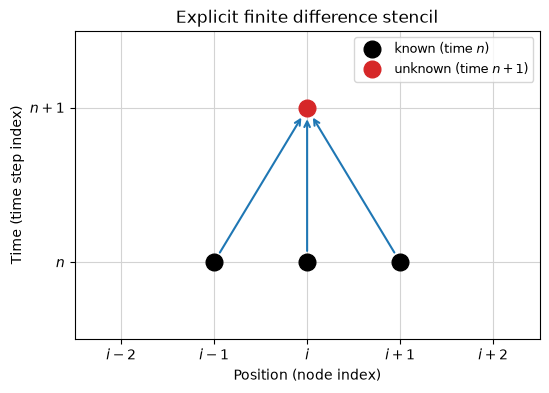

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

for i in range(-2, 3):
    ax.axvline(i, color="lightgray", linewidth=0.8, zorder=0)
for n in range(0, 2):
    ax.axhline(n, color="lightgray", linewidth=0.8, zorder=0)

known = [(-1, 0), (0, 0), (1, 0)]
weights = ["$r$", "$1-2r$", "$r$"]
target = (0, 1)

for (xi, ti), weight in zip(known, weights):
    ax.annotate(
        "",
        xy=target,
        xytext=(xi, ti),
        arrowprops=dict(arrowstyle="->", color="tab:blue", lw=1.5, shrinkA=8, shrinkB=8),
    )
    # ax.text((xi + target[0])/2 + 0.08, (ti + target[1])/3, weight, color="tab:blue", fontsize=12)

ax.plot(*zip(*known), "o", color="black", markersize=12, label="known (time $n$)")
ax.plot(*target, "o", color="tab:red", markersize=12, label="unknown (time $n+1$)")

ax.set_xticks(range(-2, 3), ["$i-2$", "$i-1$", "$i$", "$i+1$", "$i+2$"])
ax.set_yticks([0, 1], ["$n$", "$n+1$"])
ax.set(xlim=(-2.5, 2.5), ylim=(-0.5, 1.5), xlabel="Position (node index)", ylabel="Time (time step index)")
ax.set_title("Explicit finite difference stencil")
ax.legend(loc="upper right", fontsize=9)
plt.show()

## Matrix form without boundary conditions

Applying the update to every node at once can be written as a matrix-vector product, $\mathbf{c}^{n+1} = \mathbf{A}\,\mathbf{c}^n$. For $N = 5$ increments there are 6 nodes ($i = 0, \dots, 5$):

$$
\begin{bmatrix} c_0 \\ c_1 \\ c_2 \\ c_3 \\ c_4 \\ c_5 \end{bmatrix}^{n+1}
=
\begin{bmatrix}
1-2r & r & 0 & 0 & 0 & 0 \\
r & 1-2r & r & 0 & 0 & 0 \\
0 & r & 1-2r & r & 0 & 0 \\
0 & 0 & r & 1-2r & r & 0 \\
0 & 0 & 0 & r & 1-2r & r \\
0 & 0 & 0 & 0 & r & 1-2r
\end{bmatrix}
\begin{bmatrix} c_0 \\ c_1 \\ c_2 \\ c_3 \\ c_4 \\ c_5 \end{bmatrix}^{n}
$$

The interior rows ($i = 1, \dots, 4$) are complete. The first and last rows are not: the stencil at node 0 needs $c_{-1}$ and the stencil at node 5 needs $c_6$, and neither node exists. Those two rows must be replaced using the boundary conditions.

In [3]:
def update_matrix(N, r):
    """Explicit update matrix for N increments (N + 1 nodes), no boundary conditions."""
    n_nodes = N + 1
    A = (1 - 2 * r) * np.eye(n_nodes)
    A += r * np.eye(n_nodes, k=1)
    A += r * np.eye(n_nodes, k=-1)
    return A


np.set_printoptions(precision=2, suppress=True)

r_example = 0.4
print(f"Update matrix for N = 5 increments, r = {r_example}:")
print(update_matrix(5, r_example))

Update matrix for N = 5 increments, r = 0.4:
[[0.2 0.4 0.  0.  0.  0. ]
 [0.4 0.2 0.4 0.  0.  0. ]
 [0.  0.4 0.2 0.4 0.  0. ]
 [0.  0.  0.4 0.2 0.4 0. ]
 [0.  0.  0.  0.4 0.2 0.4]
 [0.  0.  0.  0.  0.4 0.2]]


## Dirichlet boundary conditions

A Dirichlet boundary condition prescribes the potential at a boundary node:

$$
c_0^n = c_\text{left}, \qquad c_N^n = c_\text{right} \qquad \text{for all } n \ge 1.
$$

The boundary values are known, so they do not need to be computed with the stencil. Instead, the first and last rows of $\mathbf{A}$ are replaced with rows of the identity matrix. Each boundary value is then copied unchanged from one time level to the next. The prescribed values are written into $\mathbf{c}$ once, before the first time step.

This works for any boundary values, so the same code covers both Case 1 ($c_\text{left} = c_0$, $c_\text{right} = 0$) and Case 3 ($c_\text{left} = c_\text{right} = 0$).

The steps are:
1. Build $\mathbf{A}$ with the stencil in every row.
2. Overwrite row $0$ and row $N$ with identity rows.
3. Set $c_0 = c_\text{left}$ and $c_N = c_\text{right}$ in the initial vector.
4. Repeat $\mathbf{c}^{n+1} = \mathbf{A}\,\mathbf{c}^n$ until the target time is reached.

In [4]:
def apply_dirichlet(A):
    """Replace the first and last rows of A with identity rows (fixed boundary values)."""
    A = A.copy()
    A[0, :] = 0.0
    A[0, 0] = 1.0
    A[-1, :] = 0.0
    A[-1, -1] = 1.0
    return A

## Full matrix with boundary conditions

For $N = 5$ increments the full system becomes

$$
\begin{bmatrix} c_0 \\ c_1 \\ c_2 \\ c_3 \\ c_4 \\ c_5 \end{bmatrix}^{n+1}
=
\begin{bmatrix}
1 & 0 & 0 & 0 & 0 & 0 \\
r & 1-2r & r & 0 & 0 & 0 \\
0 & r & 1-2r & r & 0 & 0 \\
0 & 0 & r & 1-2r & r & 0 \\
0 & 0 & 0 & r & 1-2r & r \\
0 & 0 & 0 & 0 & 0 & 1
\end{bmatrix}
\begin{bmatrix} c_0 \\ c_1 \\ c_2 \\ c_3 \\ c_4 \\ c_5 \end{bmatrix}^{n},
\qquad c_0 = c_\text{left},\ c_5 = c_\text{right}.
$$

In [5]:
print(f"Update matrix for N = 5 increments, r = {r_example}, with Dirichlet boundaries:")
print(apply_dirichlet(update_matrix(5, r_example)))

Update matrix for N = 5 increments, r = 0.4, with Dirichlet boundaries:
[[1.  0.  0.  0.  0.  0. ]
 [0.4 0.2 0.4 0.  0.  0. ]
 [0.  0.4 0.2 0.4 0.  0. ]
 [0.  0.  0.4 0.2 0.4 0. ]
 [0.  0.  0.  0.4 0.2 0.4]
 [0.  0.  0.  0.  0.  1. ]]


## Solver

The function below puts the pieces together. The time step is chosen so that $r \le 0.4$, which keeps the scheme stable, and so that the steps end exactly at the requested time.

In [6]:
def solve_diffusion(c_initial, D, L, N, t, c_left, c_right, r_max=0.4):
    """Explicit finite difference solution at time t with Dirichlet boundaries."""
    x = np.linspace(0, L, N + 1)
    dx = L / N
    n_steps = max(1, int(np.ceil(D * t / (r_max * dx**2))))
    r = D * (t / n_steps) / dx**2

    A = apply_dirichlet(update_matrix(N, r))
    c = np.full(N + 1, c_initial, dtype=float)
    c[0] = c_left
    c[-1] = c_right
    for _ in range(n_steps):
        c = A @ c
    return x, c

## Case 1: Semi-infinite medium

The initial potential is zero and the potential at $x = 0$ is held at $c_0$. A computer cannot represent an infinite domain, so the domain is cut off at a length $L$ with $c(L, t) = 0$. This is a good approximation as long as $L$ is large compared with the penetration distance $\sqrt{Dt}$.

$$
c(x, 0) = 0, \qquad c(0, t) = c_0, \qquad c(L, t) = 0.
$$

The numerical result is compared with the analytical solution $c = c_0\,\operatorname{erfc}\left(x / 2\sqrt{Dt}\right)$. Use the sliders to change the number of increments $N$, the diffusivity $D$, the time $t$ and the domain length $L$.

In [7]:
def case1_analytical(x, t, D, c0):
    return c0 * np.vectorize(erfc)(x / (2 * np.sqrt(D * t)))


def plot_case1(N=5, D=1.0, t=0.5, L=10.0, c0=1.0):
    x_num, c_num = solve_diffusion(0.0, D, L, N, t, c_left=c0, c_right=0.0)
    x_exact = np.linspace(0, L, 500)

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=x_exact, y=case1_analytical(x_exact, t, D, c0), mode="lines", name="Analytical"))
    fig.add_trace(go.Scatter(x=x_num, y=c_num, mode="lines+markers", name=f"Finite difference (N = {N})"))
    fig.update_layout(
        title=f"Case 1: semi-infinite medium, Dt = {D * t:g}",
        xaxis_title="Distance from the origin, x",
        yaxis_title="Potential c(x, t)",
        yaxis_range=[-0.05 * c0, 1.05 * c0],
        width=750,
        height=450,
    )
    fig.show()


widgets.interact(
    plot_case1,
    N=widgets.IntSlider(value=5, min=2, max=100, step=1, description="N"),
    D=widgets.FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, description="D"),
    t=widgets.FloatSlider(value=0.5, min=0.05, max=5.0, step=0.05, description="t"),
    L=widgets.FloatSlider(value=10.0, min=2.0, max=20.0, step=1.0, description="L"),
    c0=widgets.FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1, description="c0"),
);

interactive(children=(IntSlider(value=5, description='N', min=2), FloatSlider(value=1.0, description='D', max=…

## Case 3: Edges with zero potential

The initial potential is uniform and both edges are held at zero:

$$
c(x, 0) = c_0, \qquad c(0, t) = 0, \qquad c(L, t) = 0.
$$

The same solver is used with $c_\text{left} = c_\text{right} = 0$. The numerical result is compared with the analytical series solution

$$
\frac{c(x,t)}{c_0} = \frac{4}{\pi}\sum_{m=0}^{\infty}\frac{1}{2m+1}\sin\left(\frac{(2m+1)\pi x}{L}\right)\exp\left(-\frac{(2m+1)^2\pi^2Dt}{L^2}\right).
$$

In [8]:
def case3_analytical(x, t, D, L, c0, n_terms=100):
    odd_modes = 2 * np.arange(n_terms) + 1
    spatial_modes = np.sin(np.outer(odd_modes * np.pi / L, x))
    decay = np.exp(-(odd_modes**2) * np.pi**2 * D * t / L**2)
    amplitudes = 4 * c0 / (np.pi * odd_modes)
    return np.sum(amplitudes[:, None] * spatial_modes * decay[:, None], axis=0)


def plot_case3(N=5, D=1.0, t=0.1, L=2.0, c0=1.0):
    x_num, c_num = solve_diffusion(c0, D, L, N, t, c_left=0.0, c_right=0.0)
    x_exact = np.linspace(0, L, 500)

    fig = go.Figure()
    fig.add_trace(go.Scatter(x=x_exact, y=case3_analytical(x_exact, t, D, L, c0), mode="lines", name="Analytical"))
    fig.add_trace(go.Scatter(x=x_num, y=c_num, mode="lines+markers", name=f"Finite difference (N = {N})"))
    fig.update_layout(
        title=f"Case 3: edges with zero potential, Dt = {D * t:g}",
        xaxis_title="Position x",
        yaxis_title="Potential c(x, t)",
        yaxis_range=[-0.05 * c0, 1.1 * c0],
        width=750,
        height=450,
    )
    fig.show()


widgets.interact(
    plot_case3,
    N=widgets.IntSlider(value=5, min=2, max=100, step=1, description="N"),
    D=widgets.FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, description="D"),
    t=widgets.FloatSlider(value=0.1, min=0.01, max=2.0, step=0.01, description="t"),
    L=widgets.FloatSlider(value=2.0, min=1.0, max=10.0, step=0.5, description="L"),
    c0=widgets.FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1, description="c0"),
);

interactive(children=(IntSlider(value=5, description='N', min=2), FloatSlider(value=1.0, description='D', max=…